# 03 · Neural network

Your turn. Implement `build_neural_net` in `src/train.py`, then use this notebook to train it and compare it against the baselines.

Checklist:

- [ ] A small network: 2 hidden `Dense` layers with ReLU, one sigmoid output.
- [ ] `BinaryCrossentropy` loss, Adam optimizer.
- [ ] Train with `class_weight` and `validation_data=(X_cv, y_cv)`.
- [ ] Plot J_train vs J_cv per epoch. High bias or high variance?
- [ ] Add the network to the comparison table and the PR curve.

In [1]:
# Reload src/ automatically, so edits to src/train.py show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
import tensorflow as tf

from src.data import load_raw, split_by_time
from src.evaluate import confusion, evaluate, plot_pr_curves, results_table
from src.features import Preprocessor
from src.train import build_neural_net, train_logistic

tf.random.set_seed(42)  # reproducible weight initialization

In [3]:
split = split_by_time(load_raw())
prep = Preprocessor().fit(split.train)
X_train, y_train = prep.transform(split.train)
X_cv, y_cv = prep.transform(split.cv)

## Build the model

In [4]:
model = build_neural_net(n_features=X_train.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

## Train

### Choosing the fraud weight

`class_weight` makes each fraud count more in the cost function. Too little and the network ignores frauds; too much and it becomes paranoid. The right value is a hyperparameter, so it was picked on the cv set by `src/tune_fraud_weight.py`: five weights, three seeds each, with everything else fixed. The script saves its results, loaded below.

In [5]:
search = pd.read_csv("../reports/fraud_weight_search.csv")
search.groupby("fraud_weight").agg(
    pr_auc_mean=("pr_auc", "mean"),
    pr_auc_std=("pr_auc", "std"),
    missed_frauds=("missed_frauds", "mean"),
    false_alarms=("false_alarms", "mean"),
).round(3)

,pr_auc_mean,pr_auc_std,missed_frauds,false_alarms
fraud_weight,,,,
1,0.534,0.102,1756.000,95.000
10,0.736,0.059,456.333,1169.333
50,0.649,0.047,177.333,5170.333
176,0.546,0.067,56.333,14725.333
400,0.459,0.052,28.333,24771.667


A weight of 10 gives the best PR-AUC by a margin larger than the run-to-run variation. Larger weights keep cutting missed frauds at the 0.5 threshold, but they multiply false alarms and make the ranking itself worse. Without any weight (1), training is unstable: one of the three seeds learned to flag almost nothing.

In [6]:


# Train the model
FRAUD_WEIGHT = 10  # best PR-AUC in the search above

# Keras applies class_weight to the training loss only. Giving cv the same
# weights keeps J_train and J_cv on the same scale, so the curves are comparable.
cv_weights = np.where(y_cv == 1, FRAUD_WEIGHT, 1)
history = model.fit(
    X_train, y_train,
    validation_data=(X_cv, y_cv, cv_weights),
    class_weight={0: 1, 1: FRAUD_WEIGHT},
    epochs=100, batch_size=512,
)

Epoch 1/100


   1/1807 ━━━━━━━━━━━━━━━━━━━━ 13:48 459ms/step - loss: 0.7190 - pr_auc: 0.0011

  42/1807 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.7351 - pr_auc: 0.0053     

  74/1807 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.7257 - pr_auc: 0.0059

 142/1807 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.7123 - pr_auc: 0.0054

...

1134/1807 ━━━━━━━━━━━━━━━━━━━━ 0s 266us/step - loss: 0.0623 - pr_auc: 0.6685

1329/1807 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/step - loss: 0.0624 - pr_auc: 0.6664

1525/1807 ━━━━━━━━━━━━━━━━━━━━ 0s 263us/step - loss: 0.0625 - pr_auc: 0.6679

1717/1807 ━━━━━━━━━━━━━━━━━━━━ 0s 263us/step - loss: 0.0623 - pr_auc: 0.6684

1807/1807 ━━━━━━━━━━━━━━━━━━━━ 1s 362us/step - loss: 0.0622 - pr_auc: 0.6695 - val_loss: 0.0631 - val_pr_auc: 0.6879


## Learning curves: J_train vs J_cv

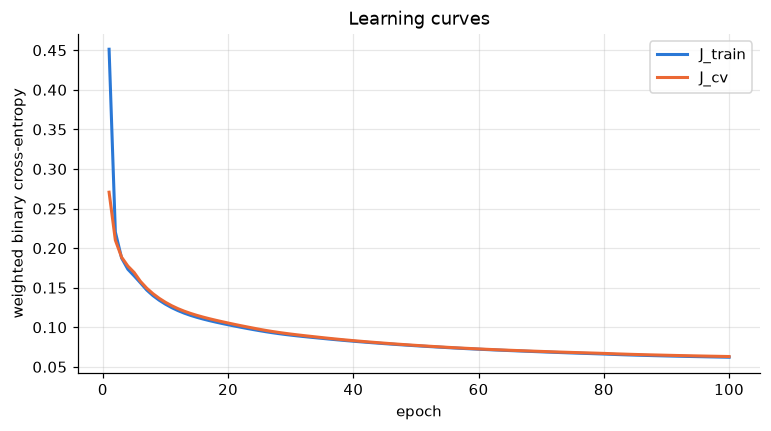

In [7]:
train_loss = history.history["loss"]
cv_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, train_loss, lw=2, label="J_train")
ax.plot(epochs, cv_loss, lw=2, label="J_cv")
ax.set_xlabel("epoch")
ax.set_ylabel("weighted binary cross-entropy")
ax.set_title("Learning curves")
ax.legend()
fig.savefig(FIGURES / "nn_learning_curves.png", bbox_inches="tight")

## Compare with the baseline

In [8]:
# The baselines are retrained on the same split, so every model is scored on the same cv set.
# The lazy model is left out: its PR curve is the dashed "random" line in the plot below.
baselines = {
    "logistic": train_logistic(X_train, y_train),
    "logistic (balanced)": train_logistic(X_train, y_train, class_weight="balanced"),
}
probs = {name: m.predict_proba(X_cv)[:, 1] for name, m in baselines.items()}
probs["neural net"] = model.predict(X_cv, verbose=0).ravel()

results_table({name: evaluate(y_cv, p) for name, p in probs.items()})

,accuracy,precision,recall,f1,pr_auc,roc_auc
neural net,0.9933,0.4737,0.8241,0.6016,0.6821,0.9917
logistic,0.9942,0.7059,0.0840,0.1501,0.3505,0.8435
logistic (balanced),0.7484,0.0179,0.7428,0.0350,0.1653,0.8598


Where do the neural net's errors fall at the default 0.5 threshold?

In [9]:
confusion(y_cv, probs["neural net"])

,pred: legit,pred: fraud
actual: legit,367446,2093
actual: fraud,402,1884


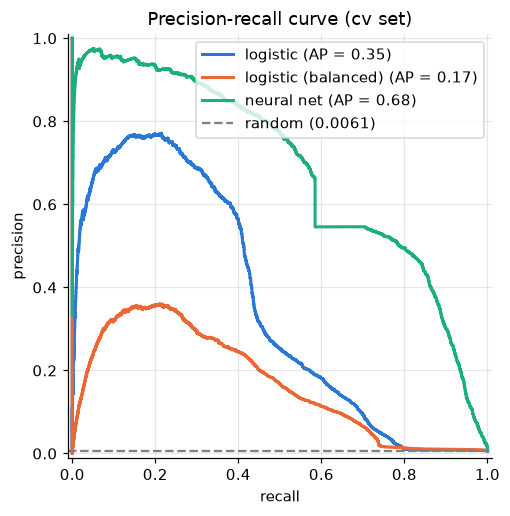

In [10]:
ax = plot_pr_curves(y_cv, probs)
ax.figure.savefig(FIGURES / "pr_curve_comparison.png", bbox_inches="tight")

## Error analysis

Which frauds does the network miss? To find out, put the network's score next to the original, readable columns and compare three groups: the frauds it caught, the frauds it missed, and legit transactions.

The threshold stays at 0.5 for now; choosing it by cost comes later (step 6).

In [11]:
THRESHOLD = 0.5
NIGHT_HOURS = [22, 23, 0, 1, 2, 3]  # the high-risk hours found in the EDA

# split.cv holds the raw cv rows in the same order as X_cv, so the scores line up.
cv = split.cv.assign(score=probs["neural net"], hour=split.cv["trans_date_trans_time"].dt.hour)
frauds = cv[cv["is_fraud"] == 1]
caught = frauds[frauds["score"] >= THRESHOLD]
missed = frauds[frauds["score"] < THRESHOLD]
legit = cv[cv["is_fraud"] == 0]
print(f"Frauds in cv: {len(frauds)} | caught: {len(caught)} | missed: {len(missed)}")

Frauds in cv: 2286 | caught: 1884 | missed: 402


### How do missed frauds differ from caught ones?

In [12]:
groups = {"missed frauds": missed, "caught frauds": caught, "legit": legit}
pd.DataFrame({
    name: {
        "transactions": len(g),
        "median amount": g["amt"].median(),
        "share at night (22h-3h)": g["hour"].isin(NIGHT_HOURS).mean(),
        "median score": g["score"].median(),
    }
    for name, g in groups.items()
}).round(3)

,missed frauds,caught frauds,legit
transactions,402.000,1884.000,369539.000
median amount,20.845,753.350,47.550
share at night (22h-3h),0.794,0.863,0.232
median score,0.179,0.895,0.001


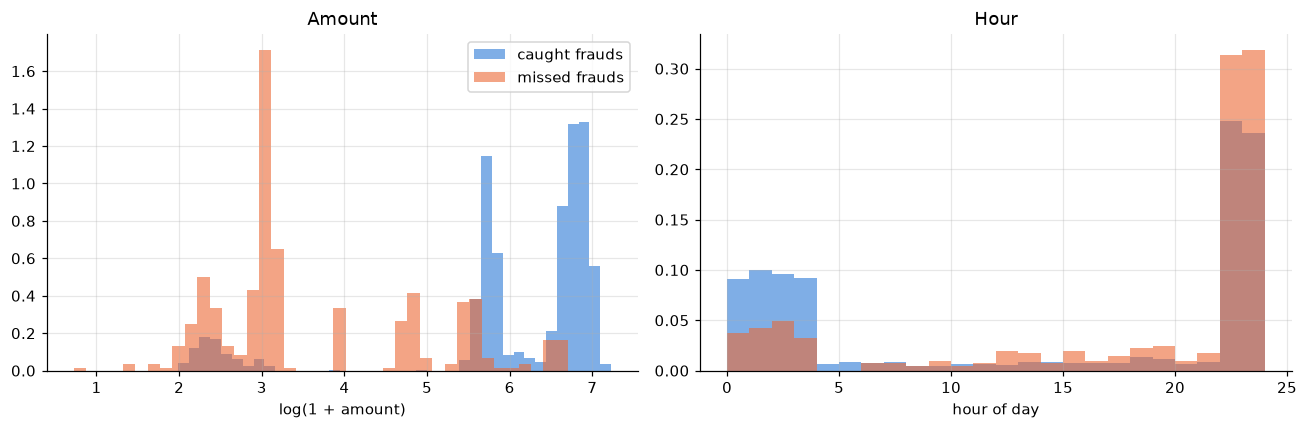

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, g, color in [("caught frauds", caught, LEGIT), ("missed frauds", missed, FRAUD)]:
    axes[0].hist(np.log1p(g["amt"]), bins=40, density=True, alpha=0.6, color=color, label=name)
    axes[1].hist(g["hour"], bins=range(25), density=True, alpha=0.6, color=color, label=name)
axes[0].set_xlabel("log(1 + amount)")
axes[0].set_title("Amount")
axes[1].set_xlabel("hour of day")
axes[1].set_title("Hour")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "error_analysis_amount_hour.png", bbox_inches="tight")

Share of each group by store category, sorted by where the network misses the most:

In [14]:
pd.DataFrame(
    {name: g["category"].value_counts(normalize=True) for name, g in groups.items()}
).round(3).sort_values("missed frauds", ascending=False)

,missed frauds,caught frauds,legit
category,,,
personal_care,0.169,NaN,0.070
kids_pets,0.167,NaN,0.087
misc_pos,0.149,0.011,0.061
food_dining,0.114,0.001,0.070
health_fitness,0.092,NaN,0.067
home,0.075,0.021,0.095
travel,0.075,NaN,0.031
grocery_pos,0.052,0.276,0.095
gas_transport,0.042,0.086,0.102


### False alarms: which legit purchases get flagged?

Missing a fraud is not the only error. Every legit purchase flagged as fraud is a customer whose card gets blocked for nothing, so it is worth asking the same question about them.

In [15]:
flagged = legit[legit["score"] >= THRESHOLD]
not_flagged = legit[legit["score"] < THRESHOLD]
print(f"Legit transactions in cv: {len(legit)} | flagged as fraud: {len(flagged)}")

pd.DataFrame({
    name: {
        "transactions": len(g),
        "median amount": g["amt"].median(),
        "share at night (22h-3h)": g["hour"].isin(NIGHT_HOURS).mean(),
        "median score": g["score"].median(),
    }
    for name, g in {"flagged legit": flagged, "not flagged legit": not_flagged, "caught frauds": caught}.items()
}).round(3)

Legit transactions in cv: 369539 | flagged as fraud: 2093


,flagged legit,not flagged legit,caught frauds
transactions,2093.00,367446.000,1884.000
median amount,855.63,47.210,753.350
share at night (22h-3h),0.25,0.232,0.863
median score,0.74,0.001,0.895


### One card, up close

Statistics hide the story of a single card. Below are all transactions of the card with the most missed frauds, from two days before its first fraud until the last one.

In [16]:
card = missed["cc_num"].value_counts().index[0]
card_frauds = frauds[frauds["cc_num"] == card]
window = (cv["cc_num"] == card) & cv["trans_date_trans_time"].between(
    card_frauds["trans_date_trans_time"].min() - pd.Timedelta(days=2),
    card_frauds["trans_date_trans_time"].max(),
)
cv.loc[window, ["trans_date_trans_time", "category", "amt", "is_fraud", "score"]].round(3)

/var/folders/z8/k3_rp8d93l9bj0jrg7tqvysr0000gn/T/ipykernel_87272/1033228747.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  cv.loc[window, ["trans_date_trans_time", "category", "amt", "is_fraud", "score"]].round(3)


,trans_date_trans_time,category,amt,is_fraud,score
1182225,2020-05-09 01:04:05,shopping_pos,1026.44,1,0.740
1182326,2020-05-09 02:29:34,grocery_pos,392.35,1,0.740
1183937,2020-05-09 23:03:21,kids_pets,17.13,1,0.347
1184085,2020-05-10 00:45:08,shopping_pos,759.90,1,0.712
1184241,2020-05-10 02:14:40,food_dining,118.22,1,0.138
1184244,2020-05-10 02:16:00,misc_pos,8.29,1,0.044
1184251,2020-05-10 02:24:54,shopping_net,803.43,1,0.597
1184326,2020-05-10 03:19:16,shopping_pos,734.72,1,0.639
1184373,2020-05-10 03:47:47,shopping_net,971.53,1,0.740
1185926,2020-05-10 18:18:02,kids_pets,17.99,1,0.059


### What do the errors have in common?

TODO (you): look at the tables and plots above and write down what you see. Some questions to guide you:

1. Are the missed frauds small or large purchases compared with the caught ones? Do they happen at night or during the day?
2. Do some store categories hide frauds better than others?
3. What do the falsely flagged legit purchases look like? Why would the network confuse them with fraud?
4. On the card above: what changes in the card's behaviour when the fraud starts? Could the network see that change, given that each transaction is scored on its own?

## Conclusions

TODO (you): answer in a few sentences.

1. Learning curves: high bias, high variance, or neither? Back it up with what the plot shows.
2. Does the neural net beat the best logistic regression on PR-AUC? By how much?
3. Looking at the PR curve: in which recall range is each model better?
4. Based on the error analysis, what would you try next, and why?